# 02 · Modelos sobre variables tabulares (Enfoque A · E-04 y E-05)

Comparamos cuatro modelos de Machine Learning clásico en cuatro escenarios que van **de más a menos atajos**:

| Escenario | Variables | ¿Por qué? |
|---|---|---|
| **A1 · Todas** | las 50 numéricas del dataset | comparable con la literatura sobre PhiUSIIL |
| **A2 · Sin URLSimilarityIndex** | 49 | quita la variable que separa casi perfecto |
| **A3 · Solo URL** | las 21 calculadas del texto de la URL | no requiere descargar la página |
| **A4 · Léxicas del dominio** | ~46 variables **propias**, calculadas solo con el dominio | sin los atajos `https://www.` ni la ruta |

Modelos (elegidos de más simple a más complejo):

- **Regresión logística**: línea base lineal e interpretable.
- **Random Forest**: muchos árboles de decisión que votan; robusto y casi sin ajustes.
- **XGBoost**: árboles construidos uno tras otro, cada uno corrigiendo los errores del anterior (*boosting*); suele ser el mejor en datos tabulares.
- **MLP**: red neuronal densa pequeña (Deep Learning sobre tabla).

Todos se entrenan con **train** y se comparan en **validación**. El conjunto de **test** no se toca aquí: se usa una sola vez en `04_evaluacion_final.ipynb`.

In [1]:
import sys, time, json, warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
from src import datos, caracteristicas, evaluacion

DIR_FIG = RAIZ / "reports" / "figures"; DIR_FIG.mkdir(parents=True, exist_ok=True)
DIR_RES = RAIZ / "reports" / "resultados"; DIR_RES.mkdir(parents=True, exist_ok=True)
DIR_MOD = RAIZ / "models"; DIR_MOD.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
SEMILLA = datos.SEMILLA

def guardar(fig, nombre):
    fig.savefig(DIR_FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")

## 1. Datos y escenarios

In [2]:
df, train, val, test = datos.cargar_conjuntos()
print(f"train: {len(train):,} | val: {len(val):,} | test: {len(test):,} (no se usa aquí)")

# Variables léxicas propias, calculadas solo con el dominio (escenario A4)
lex_train = caracteristicas.variables_lexicas(train.dominio_base)
lex_val = caracteristicas.variables_lexicas(val.dominio_base)
print(f"Variables léxicas propias: {lex_train.shape[1]}")

todas = datos.COLS_URL + datos.COLS_SOSPECHOSAS + datos.COLS_PAGINA
ESCENARIOS = {
    "A1 · Todas": (train[todas], val[todas]),
    "A2 · Sin URLSimilarityIndex": (train[datos.COLS_URL + datos.COLS_PAGINA], val[datos.COLS_URL + datos.COLS_PAGINA]),
    "A3 · Solo URL": (train[datos.COLS_URL], val[datos.COLS_URL]),
    "A4 · Léxicas del dominio": (lex_train, lex_val),
}
y_train, y_val = train.es_phishing.values, val.es_phishing.values
for nombre, (Xtr, Xva) in ESCENARIOS.items():
    assert (Xtr.values >= 0).all(), "log1p requiere valores no negativos"
    print(f"{nombre:30s} {Xtr.shape[1]:3d} variables")

train: 164,918 | val: 35,206 | test: 35,246 (no se usa aquí)


Variables léxicas propias: 46
A1 · Todas                      50 variables
A2 · Sin URLSimilarityIndex     49 variables
A3 · Solo URL                   21 variables
A4 · Léxicas del dominio        46 variables


## 2. Definición de los modelos

- Regresión logística y MLP son sensibles a la escala de las variables: aplicamos `log1p` (comprime colas largas, como páginas con 100.000 líneas de código) y luego `StandardScaler` (media 0, desviación 1). Los árboles no lo necesitan.
- Se usa un `Pipeline` para que la transformación se **aprenda solo con train** y se aplique igual a val y test.

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

def escalar():
    return [FunctionTransformer(np.log1p), StandardScaler()]

MODELOS = {
    "Regresión logística": lambda: make_pipeline(*escalar(), LogisticRegression(max_iter=2000)),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=150, min_samples_leaf=2,
                                                    n_jobs=-1, random_state=SEMILLA),
    "XGBoost": lambda: XGBClassifier(n_estimators=400, learning_rate=0.1, max_depth=6,
                                     subsample=0.9, colsample_bytree=0.9, tree_method="hist",
                                     eval_metric="logloss", n_jobs=-1, random_state=SEMILLA),
    "MLP": lambda: make_pipeline(*escalar(), MLPClassifier(hidden_layer_sizes=(64, 32),
                                 early_stopping=True, max_iter=60, random_state=SEMILLA)),
}

## 3. Entrenamiento y comparación en validación (4 escenarios × 4 modelos)

In [4]:
filas, entrenados = [], {}
for esc, (Xtr, Xva) in ESCENARIOS.items():
    for nom, crear in MODELOS.items():
        modelo = crear()
        t0 = time.time()
        modelo.fit(Xtr, y_train)
        seg = time.time() - t0
        prob = modelo.predict_proba(Xva)[:, 1]          # probabilidad de phishing
        m = evaluacion.metricas(y_val, prob)
        filas.append({"escenario": esc, "modelo": nom, **m, "segundos_entrenamiento": round(seg, 1)})
        entrenados[(esc, nom)] = modelo
        print(f"{esc:30s} {nom:20s} F1={m['f1']:.4f}  recall={m['recall']:.4f}  ({seg:.0f} s)")

res_val = pd.DataFrame(filas)
res_val.to_csv(DIR_RES / "val_tabulares.csv", index=False)

A1 · Todas                     Regresión logística  F1=0.9998  recall=0.9997  (0 s)


A1 · Todas                     Random Forest        F1=0.9999  recall=0.9999  (7 s)


A1 · Todas                     XGBoost              F1=0.9999  recall=0.9999  (2 s)


A1 · Todas                     MLP                  F1=0.9999  recall=0.9999  (4 s)


A2 · Sin URLSimilarityIndex    Regresión logística  F1=0.9999  recall=0.9999  (0 s)


A2 · Sin URLSimilarityIndex    Random Forest        F1=0.9999  recall=0.9999  (12 s)


... (6 outputs left out)

A4 · Léxicas del dominio       Regresión logística  F1=0.7349  recall=0.6427  (1 s)


A4 · Léxicas del dominio       Random Forest        F1=0.7583  recall=0.6539  (8 s)


A4 · Léxicas del dominio       XGBoost              F1=0.7611  recall=0.6470  (3 s)


A4 · Léxicas del dominio       MLP                  F1=0.7609  recall=0.6473  (12 s)


In [5]:
cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "segundos_entrenamiento"]
display(res_val.set_index(["escenario", "modelo"])[cols].style.format("{:.4f}", subset=cols[:-1])
        .background_gradient(subset=["f1"], cmap="Blues"))

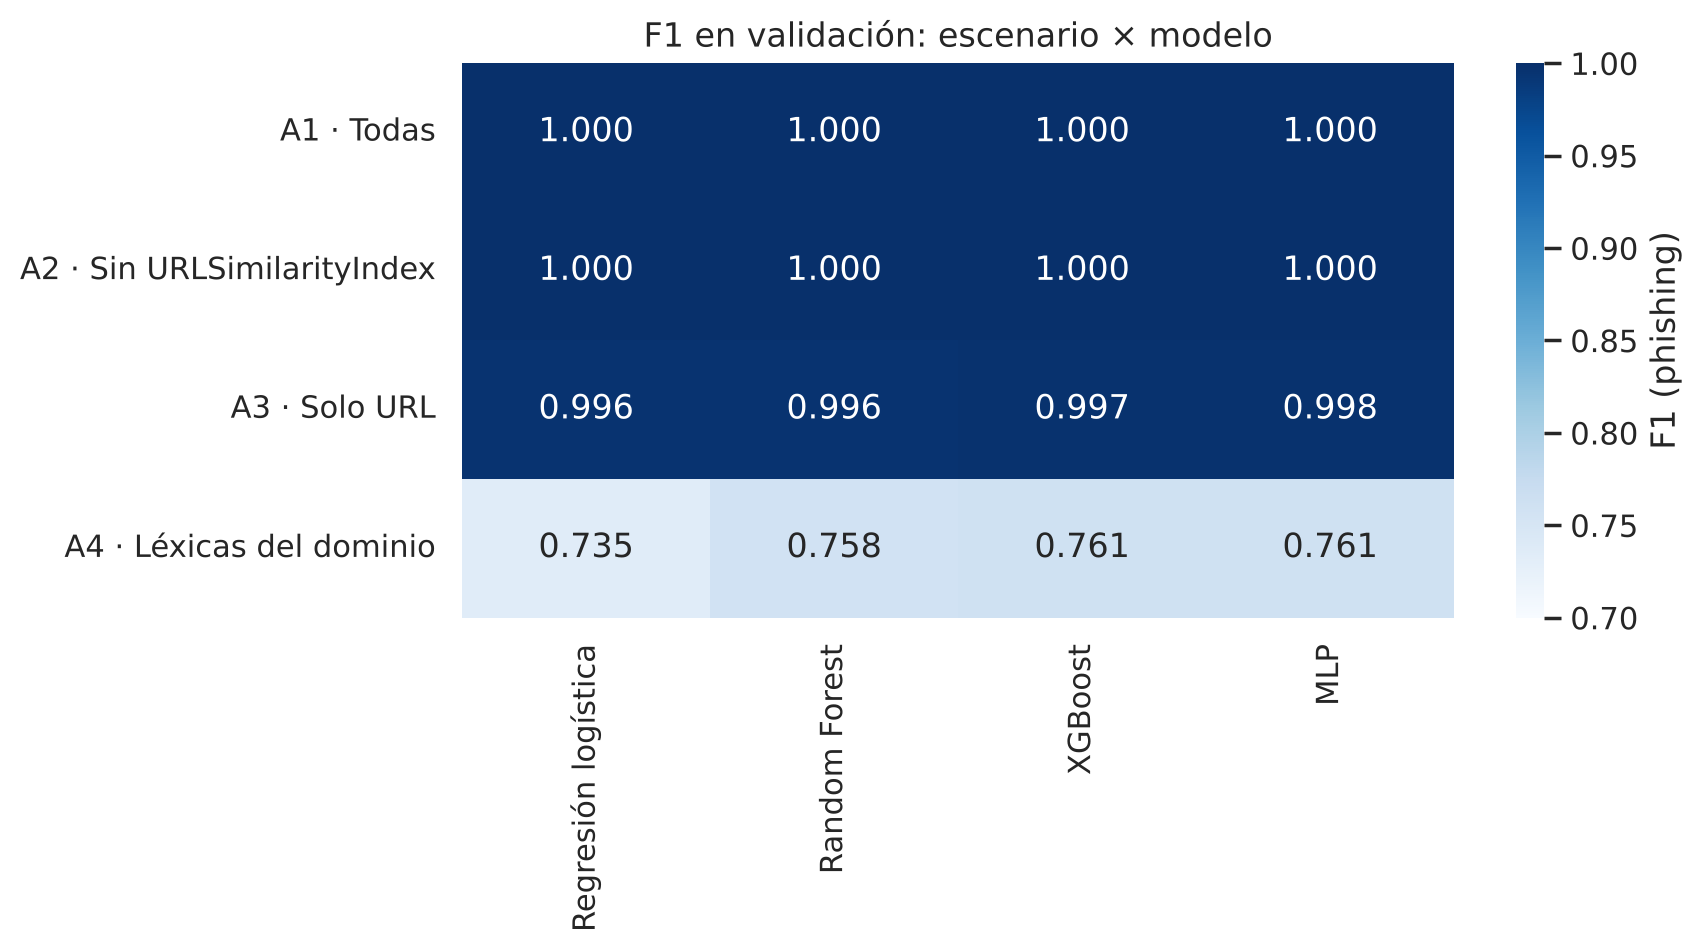

In [6]:
pivote = res_val.pivot(index="escenario", columns="modelo", values="f1")[list(MODELOS)]
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(pivote, annot=True, fmt=".3f", cmap="Blues", vmin=0.7, vmax=1.0, cbar_kws={"label": "F1 (phishing)"}, ax=ax)
ax.set_xlabel(""); ax.set_ylabel(""); ax.set_title("F1 en validación: escenario × modelo")
guardar(fig, "07_tabulares_f1_val"); plt.show()

**Cómo leerlo:**

- En **A1, A2 y A3** todos los modelos basados en árboles superan ~0,99 de F1. Incluso **A3 (solo variables de la URL)** sigue casi perfecto porque esas variables se calcularon sobre la URL completa: el largo, la cantidad de `/` o `IsHTTPS` delatan el atajo "las legítimas no tienen ruta y usan https".
- En A1 y A2 hasta la **regresión logística** supera 0,999: si un modelo lineal simple acierta casi todo, el problema "es demasiado fácil", otra señal de atajos.
- **A4** es el único escenario sin atajos y el F1 baja a ~0,76: es el desempeño "honesto" de un modelo tabular que solo mira el dominio. Además el **recall** cae a ~0,65: un tercio de los phishing se escapa.
- En A4, XGBoost, Random Forest y MLP quedan cerca; la regresión logística es la más débil porque la relación entre variables y phishing no es lineal.

## 4. Ajuste de hiperparámetros de XGBoost en A4

Los hiperparámetros son la "configuración" del modelo que no se aprende de los datos (cuántos árboles, qué tan profundos, qué tan rápido aprende). Probamos una grilla pequeña y elegimos la mejor según **F1 en validación**. Usamos `early_stopping_rounds`: si la pérdida en validación no mejora en 30 rondas, se detiene (evita sobreajuste).

In [7]:
from itertools import product

Xtr4, Xva4 = ESCENARIOS["A4 · Léxicas del dominio"]
grilla = list(product([4, 6, 8], [0.05, 0.1], [1, 5]))   # max_depth, learning_rate, min_child_weight
filas_aj = []
for prof, lr, mcw in grilla:
    m = XGBClassifier(n_estimators=1500, learning_rate=lr, max_depth=prof, min_child_weight=mcw,
                      subsample=0.9, colsample_bytree=0.9, tree_method="hist", eval_metric="logloss",
                      early_stopping_rounds=30, n_jobs=-1, random_state=SEMILLA)
    m.fit(Xtr4, y_train, eval_set=[(Xva4, y_val)], verbose=False)
    met = evaluacion.metricas(y_val, m.predict_proba(Xva4)[:, 1])
    filas_aj.append({"max_depth": prof, "learning_rate": lr, "min_child_weight": mcw,
                     "arboles": m.best_iteration + 1, "f1": met["f1"], "roc_auc": met["roc_auc"]})

ajuste = pd.DataFrame(filas_aj).sort_values("f1", ascending=False)
ajuste.to_csv(DIR_RES / "ajuste_xgb_a4.csv", index=False)
display(ajuste.head(6).style.format({"learning_rate": "{:.2f}", "f1": "{:.4f}", "roc_auc": "{:.4f}"}))
mejor = ajuste.iloc[0]
print("Mejor configuración:", mejor.drop(["f1", "roc_auc"]).to_dict())

,max_depth,learning_rate,min_child_weight,arboles,f1,roc_auc
10,8,0.10,1,260,0.7716,0.8839
11,8,0.10,5,186,0.7716,0.8824
7,6,0.10,5,342,0.7714,0.8827
9,8,0.05,5,492,0.7711,0.8830
8,8,0.05,1,423,0.7707,0.8832
5,6,0.05,5,625,0.7706,0.8823


Mejor configuración: {'max_depth': 8.0, 'learning_rate': 0.1, 'min_child_weight': 1.0, 'arboles': 260.0}


In [8]:
xgb_a4 = XGBClassifier(n_estimators=int(mejor.arboles), learning_rate=mejor.learning_rate,
                       max_depth=int(mejor.max_depth), min_child_weight=int(mejor.min_child_weight),
                       subsample=0.9, colsample_bytree=0.9, tree_method="hist",
                       eval_metric="logloss", n_jobs=-1, random_state=SEMILLA)
xgb_a4.fit(Xtr4, y_train)
m_aj = evaluacion.metricas(y_val, xgb_a4.predict_proba(Xva4)[:, 1])
m_base = res_val.query("escenario == 'A4 · Léxicas del dominio' and modelo == 'XGBoost'").iloc[0]
print(f"XGBoost A4 sin ajuste: F1 = {m_base.f1:.4f} | con ajuste: F1 = {m_aj['f1']:.4f}")
entrenados[("A4 · Léxicas del dominio", "XGBoost (ajustado)")] = xgb_a4
res_val = pd.concat([res_val, pd.DataFrame([{"escenario": "A4 · Léxicas del dominio",
                     "modelo": "XGBoost (ajustado)", **m_aj}])], ignore_index=True)
res_val.to_csv(DIR_RES / "val_tabulares.csv", index=False)

XGBoost A4 sin ajuste: F1 = 0.7611 | con ajuste: F1 = 0.7716


## 5. ¿En qué se fija el modelo? (SHAP)

**SHAP** asigna a cada variable cuánto empujó la predicción hacia phishing (+) o hacia legítima (−) en cada URL. Promediando su valor absoluto obtenemos la importancia de cada variable. Lo comparamos en dos escenarios:

- **A2** (con atajos de la página y la URL).
- **A4** (solo el dominio).

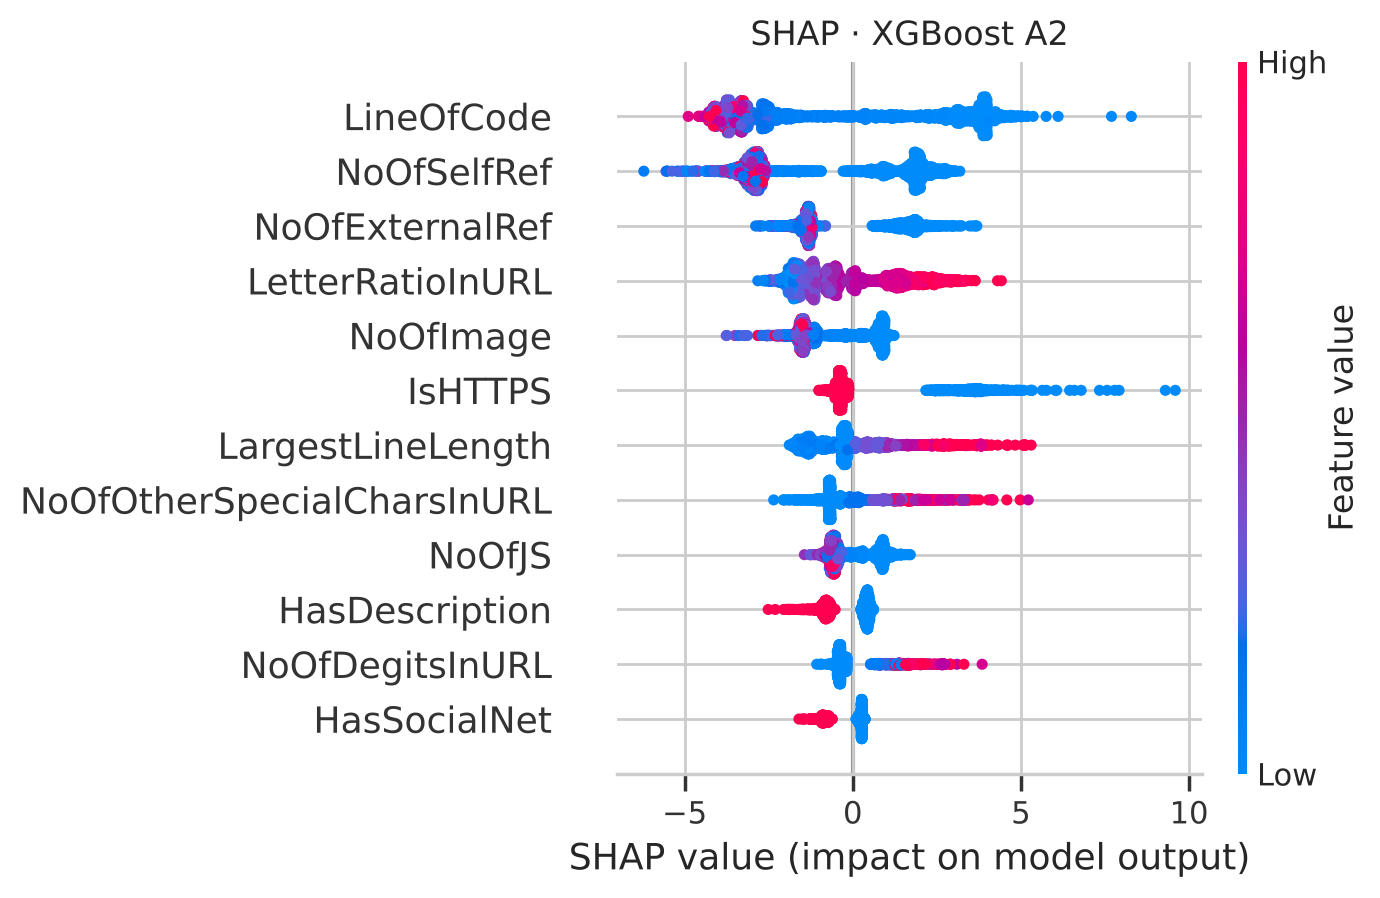

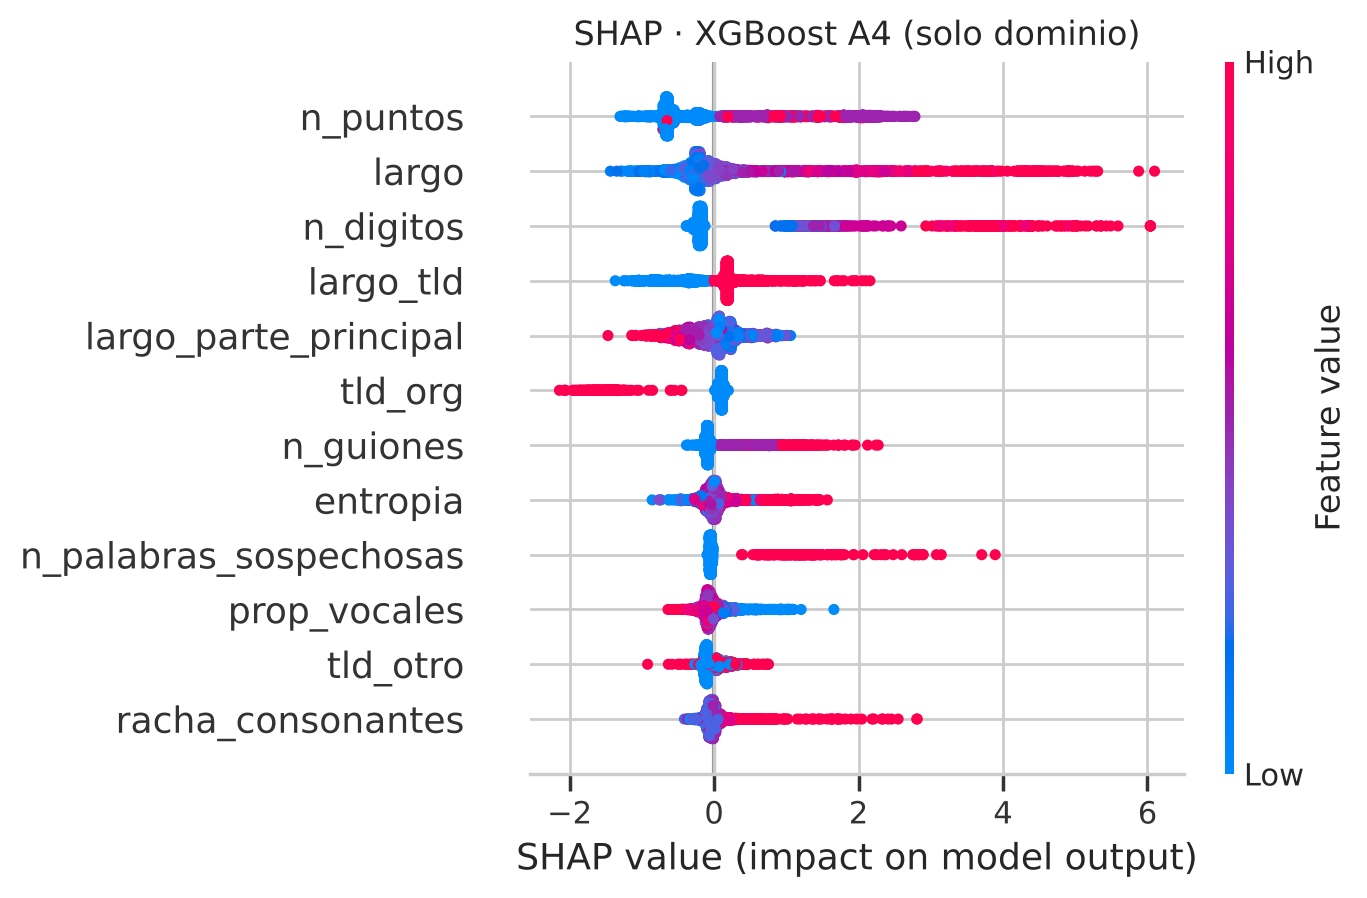

,A2: variable,A2: |SHAP|,A4: variable,A4: |SHAP|
0,LineOfCode,3.127,n_puntos,0.809
1,NoOfSelfRef,2.410,largo,0.663
2,NoOfExternalRef,1.523,n_digitos,0.621
3,LetterRatioInURL,1.309,largo_tld,0.349
4,NoOfImage,1.111,largo_parte_principal,0.272
5,IsHTTPS,1.058,tld_org,0.206
6,LargestLineLength,0.964,n_guiones,0.203
7,NoOfOtherSpecialCharsInURL,0.813,entropia,0.156


In [9]:
import shap

def grafico_shap(modelo, X, titulo, nombre, n=3000):
    muestra = X.sample(n, random_state=SEMILLA)
    valores = shap.TreeExplainer(modelo).shap_values(muestra)
    plt.figure()
    shap.summary_plot(valores, muestra, max_display=12, show=False, plot_size=(7, 4.5))
    plt.title(titulo); fig = plt.gcf()
    guardar(fig, nombre); plt.show()
    return pd.Series(np.abs(valores).mean(0), index=X.columns).sort_values(ascending=False)

imp_a2 = grafico_shap(entrenados[("A2 · Sin URLSimilarityIndex", "XGBoost")],
                      ESCENARIOS["A2 · Sin URLSimilarityIndex"][1], "SHAP · XGBoost A2", "08_shap_a2")
imp_a4 = grafico_shap(xgb_a4, Xva4, "SHAP · XGBoost A4 (solo dominio)", "09_shap_a4")
pd.DataFrame({"A2: variable": imp_a2.index[:8], "A2: |SHAP|": imp_a2.values[:8].round(3),
              "A4: variable": imp_a4.index[:8], "A4: |SHAP|": imp_a4.values[:8].round(3)})

**Lectura:**

- En **A2** dominan variables de la página (líneas de código, referencias externas, imágenes) y de forma de la URL (`IsHTTPS`, caracteres especiales): son justamente las que reflejan el atajo de cómo se recolectaron las URLs.
- En **A4** el modelo se apoya en señales con sentido: la cantidad de puntos (subdominios, como en `login.cuenta.ejemplo.com`), el largo, los dígitos, el largo del TLD, los guiones y la entropía del dominio.

Cada punto del gráfico es una URL; el color indica si el valor de la variable es alto (rojo) o bajo (azul), y la posición horizontal cuánto empujó hacia phishing (derecha) o legítima (izquierda).

## 6. Selección y guardado de modelos

Para cada escenario guardamos el mejor modelo según F1 en validación. Estos son los que se evalúan en test en el notebook 04.

In [10]:
seleccion = {}
for esc in ESCENARIOS:
    fila = res_val[res_val.escenario == esc].sort_values("f1", ascending=False).iloc[0]
    modelo = entrenados[(esc, fila.modelo)]
    archivo = f"tab_{esc.split(' ')[0]}.joblib"
    joblib.dump(modelo, DIR_MOD / archivo, compress=3)
    seleccion[esc] = {"modelo": fila.modelo, "archivo": archivo, "f1_val": round(fila.f1, 4)}
    print(f"{esc:30s} -> {fila.modelo:20s} F1 val = {fila.f1:.4f}  ({(DIR_MOD / archivo).stat().st_size / 1e6:.1f} MB)")

(DIR_RES / "seleccion_tabulares.json").write_text(json.dumps(seleccion, ensure_ascii=False, indent=2))

A1 · Todas                     -> Random Forest        F1 val = 0.9999  (0.8 MB)
A2 · Sin URLSimilarityIndex    -> MLP                  F1 val = 0.9999  (0.1 MB)
A3 · Solo URL                  -> MLP                  F1 val = 0.9976  (0.1 MB)
A4 · Léxicas del dominio       -> XGBoost (ajustado)   F1 val = 0.7716  (0.6 MB)


449

## 7. Conclusiones de este notebook

1. Con las variables originales del dataset (A1–A3) cualquier modelo de árboles llega a F1 ≈ 0,99–1,00, igual que la literatura. Pero ese resultado se explica por los atajos, no por detectar phishing.
2. Quitar `URLSimilarityIndex` (A2) o las variables de la página (A3) **no basta**: las variables de la URL también se calcularon sobre la URL completa y heredan el atajo.
3. Con variables propias del dominio (A4), el mejor modelo tabular (XGBoost ajustado) obtiene F1 ≈ 0,77 en validación. Ese es el punto de comparación justo para los modelos de texto del notebook 03.
4. En el escenario honesto (A4) los modelos no lineales (XGBoost, Random Forest, MLP) superan a la regresión logística; el ajuste de hiperparámetros de XGBoost aporta cerca de 1 punto de F1.